# Module 3 — Subcategory classifier: MLP on TF-IDF

**Goal:** given a travel message, predict **which of the 15 subcategories** it belongs to (the category follows from it).

```
"9adech el billet men tunis l paris ghodwa ?"
      ↓ (NER, Module 4) places and dates are replaced by tags
"9adech el billet men <LOC> l <LOC> <DATE> ?"      ← INPUT of this model
      ↓ TF-IDF → MLP → softmax
flight_price 91% | flight_search 6% | ...          ← OUTPUT  →  category = flights
```

**Why the masked text?** So the model learns the **intent** from the words (`9adech` + `billet` = ticket price), not shortcuts from city names (e.g. "Jeddah → visa").

### The two parts of the model
1. **TF-IDF** turns each message into a long list of numbers, **one per word of the vocabulary**: how important each word is for this message (TF = how often it appears in the message × IDF = how rare it is across the training messages). The vocabulary and the IDF values are learned **once, from train only**, then frozen.
2. **The MLP** (multi-layer perceptron) reads that list: a **hidden layer** of neurons with ReLU learns "detectors" (price words, flight words, luggage words…), and an **output layer** of 15 neurons + softmax turns them into 15 probabilities.

### The data
Only **travel** messages (the travel filter removed the others before this model runs). All 3 languages are mixed in one model.
| set | used for |
|---|---|
| **train** | learning the vocabulary, the IDF values and the MLP's weights |
| **val** | choosing settings, early stopping, diagnosis |
| **test** | final exam at the very end (**not used here**) |

## 0. Setup

Load the travel rows of train and val. For each one we keep:
- the **input**: `text_masked`, cleaned with the same `normalize()` as Module 1 (lowercase, spaces around punctuation, digits and accents kept);
- the **label**: `subcategory` (the truth the model must learn), plus `lang` to analyse results per language.

What to check: the 15 subcategories should have roughly the same number of training messages (a **balanced** dataset).

In [1]:
import sys, json
from pathlib import Path
from collections import Counter

ROOT = Path.cwd()
while not (ROOT / "CLAUDE.md").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.preprocessing.normalize import normalize
from src.labels import SUBCATEGORIES, SUBCAT_TO_CAT, LANGS

def load_travel(split):
    rows = [json.loads(line) for line in open(ROOT / "data" / "processed" / f"{split}.jsonl", encoding="utf-8")]
    return [r for r in rows if r["is_travel"]]          # non-travel messages never reach this model

train, val = load_travel("train"), load_travel("val")
X_train_text = [normalize(r["text_masked"]) for r in train]
X_val_text = [normalize(r["text_masked"]) for r in val]
y_train = [r["subcategory"] for r in train]
y_val = [r["subcategory"] for r in val]

print(f"TRAIN: {len(train)} travel messages | VAL: {len(val)} travel messages\n")
counts = Counter(y_train)
for sub in SUBCATEGORIES:
    print(f"  {SUBCAT_TO_CAT[sub]:16s} {sub:17s} train {counts[sub]:3d}")
print("\nFirst 5 training inputs (masked + normalized):")
for text, label in list(zip(X_train_text, y_train))[:5]:
    print(f"  {label:17s} | {text}")

TRAIN: 2680 travel messages | VAL: 581 travel messages

  flights          flight_search     train 184
  flights          flight_price      train 182
  flights          baggage           train 174
  accommodation    hotel_search      train 182
  accommodation    hotel_price       train 183
  accommodation    hotel_facilities  train 161
  local_transport  car_rental        train 184
  local_transport  transfer_taxi     train 182
  local_transport  public_transport  train 183
  destination_info weather           train 175
  destination_info activities        train 182
  destination_info visa_documents    train 178
  budget_money     exchange_rate     train 182
  budget_money     trip_cost         train 178
  budget_money     payment_methods   train 170

First 5 training inputs (masked + normalized):
  flight_search     | is there a morning flight from <loc> to <loc>
  flight_search     | is there a direct flight between <loc> and <loc> ?
  flight_search     | hi , i'd like to travel to <

## 1. TF-IDF: from text to numbers

### Step 1a: the vocabulary
`TfidfVectorizer` cuts every **training** message into words and builds the **vocabulary**: the list of all words seen in train, each with a fixed position (a column number). For now we use **whole words only** (word pairs and character pieces can be added later, if they help).

One setting needs attention: by default scikit-learn **drops one-letter words**. In Tunisian, one-letter words matter a lot (`l` = to, `f` = in, `w` = and, `b` = with), so we keep them with `token_pattern = r"\b\w+\b"` ("any word of 1 or more letters/digits"). The tags `<loc>` / `<date>` become the words `loc` / `date`.

### Step 1b: the IDF values
For every vocabulary word, scikit-learn computes its IDF from the **training** messages:

  **IDF(word) = ln( (1 + N) / (1 + number of training messages containing the word) ) + 1**   (N = 2,680)

It is the formula from our explanation plus two small "+1" safety terms (so no division by zero, and the most common words get a minimum of 1 instead of 0). **Common words get a low IDF, rare telling words a high IDF.**

### Step 1c: one message → one vector
`tfidf.transform(...)` turns a message into a list of numbers **as long as the vocabulary**: the TF-IDF of each word of the message at its position, **0 everywhere else**, then scaled to length 1 (normalization). Words not in the vocabulary are ignored.

The code fits the vectorizer **on train only** (`fit_transform`), then shows: the vocabulary size, the most common and the rarest words, the IDF of a few interesting words, and the full vector of one example message.

In [2]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(token_pattern=r"(?u)\b\w+\b")      # whole words, including 1-letter words
X_train = tfidf.fit_transform(X_train_text)                 # learns vocabulary + IDF from TRAIN ONLY
X_val = tfidf.transform(X_val_text)                         # val is only transformed, never "fitted"

vocab = tfidf.get_feature_names_out()
idf = tfidf.idf_
print(f"Vocabulary: {len(vocab)} words  ->  every message becomes a vector of {len(vocab)} numbers")
print(f"X_train shape: {X_train.shape}  (messages x words)\n")

order = idf.argsort()
print("10 MOST COMMON words (lowest IDF = least informative):")
print("  ", ", ".join(f"{vocab[i]} ({idf[i]:.2f})" for i in order[:10]))
print("\n10 RAREST words (highest IDF; seen in only 1 training message):")
print("  ", ", ".join(f"{vocab[i]} ({idf[i]:.2f})" for i in order[-10:]))

print("\nIDF of some interesting words:")
for word in ["loc", "el", "9adech", "combien", "much", "billet", "valise", "météo", "karhba"]:
    j = tfidf.vocabulary_.get(word)
    print(f"   {word:8s} {'not in vocabulary' if j is None else f'{idf[j]:.2f}'}")

example = normalize("9adech el billet l <LOC> <DATE> ?")
vector = tfidf.transform([example])
print(f"\nExample message: {example!r}")
print(f"Its vector has {vector.shape[1]} numbers, of which only {vector.nnz} are not zero:")
for j, value in sorted(zip(vector.indices, vector.data), key=lambda t: -t[1]):
    print(f"   position {j:4d}  {vocab[j]:8s} TF-IDF = {value:.3f}   (IDF {idf[j]:.2f})")
print("   ('?' is not a word for the vectorizer, so it is ignored)")

Vocabulary: 1816 words  ->  every message becomes a vector of 1816 numbers
X_train shape: (2680, 1816)  (messages x words)

10 MOST COMMON words (lowest IDF = least informative):
   loc (1.17), date (2.54), a (2.58), à (2.73), in (2.79), l (2.95), to (3.05), pour (3.10), de (3.27), f (3.28)

10 RAREST words (highest IDF; seen in only 1 training message):
   charging (8.20), operating (8.20), certificat (8.20), organisées (8.20), originale (8.20), our (8.20), outside (8.20), overall (8.20), no (8.20), ma9boul (8.20)

IDF of some interesting words:
   loc      1.17
   el       3.64
   9adech   3.97
   combien  4.12
   much     4.56
   billet   4.65
   valise   5.23
   météo    6.81
   karhba   5.13

Example message: '9adech el billet l <loc> <date> ?'
Its vector has 1816 numbers, of which only 6 are not zero:
   position  268  billet   TF-IDF = 0.567   (IDF 4.65)
   position   60  9adech   TF-IDF = 0.484   (IDF 3.97)
   position  566  el       TF-IDF = 0.444   (IDF 3.64)
   position  838

## 2. The first MLP, trained epoch by epoch

### The network
```
TF-IDF vector (1,816 numbers) → hidden layer: 256 neurons + ReLU → output layer: 15 neurons → softmax → 15 probabilities
```
Number of weights to learn: 1,816 × 256 + 256 (hidden) + 256 × 15 + 15 (output) ≈ **469,000**, all starting as small random numbers.

### The settings (scikit-learn `MLPClassifier`)
| setting | value | meaning |
|---|---|---|
| `hidden_layer_sizes` | (256,) | one hidden layer of 256 neurons |
| `activation` | relu | negative → 0 (the "detector on/off" step) |
| `solver` | adam | the optimizer: gradient descent with an adaptive step size per weight |
| `learning_rate_init` | 0.001 | Adam's base step size |
| `batch_size` | 32 | the weights are updated after every 32 messages (one **mini-batch**) |
| `alpha` | 0.0001 | the **L2 penalty**: a small cost for big weights (against memorizing); tiny for now |
| `random_state` | 42 | the same random starting weights every run |

### Training epoch by epoch
`mlp.partial_fit(...)` does **one epoch**: one pass over the 2,680 training messages, in shuffled mini-batches of 32. That's about 84 weight updates, each one doing *forward pass → loss → backpropagation → update*, exactly like our hand simulation.

Unlike fastText, we can **measure after each epoch** of a single training run. After every epoch we compute **loss and accuracy on train and on val**, so we get true learning curves. We train for 40 epochs (about a minute) and keep track of the epoch where **val loss** is lowest.

epoch | train loss  val loss | train acc  val acc
    1 |     2.2171    2.3132 |    92.57%   79.00%
    2 |     0.9888    1.2899 |    96.38%   82.44%
    3 |     0.3568    0.7381 |    98.43%   85.20%
    5 |     0.0976    0.4858 |    99.81%   87.78%
    8 |     0.0331    0.4137 |   100.00%   88.47%
   10 |     0.0204    0.3990 |   100.00%   88.47%
   15 |     0.0087    0.3882 |   100.00%   88.98%
   20 |     0.0048    0.3884 |   100.00%   88.98%
   30 |     0.0021    0.3955 |   100.00%   88.81%
   40 |     0.0012    0.4033 |   100.00%   88.81%

Lowest val loss at epoch 17: 0.3876 (val accuracy 88.98%)


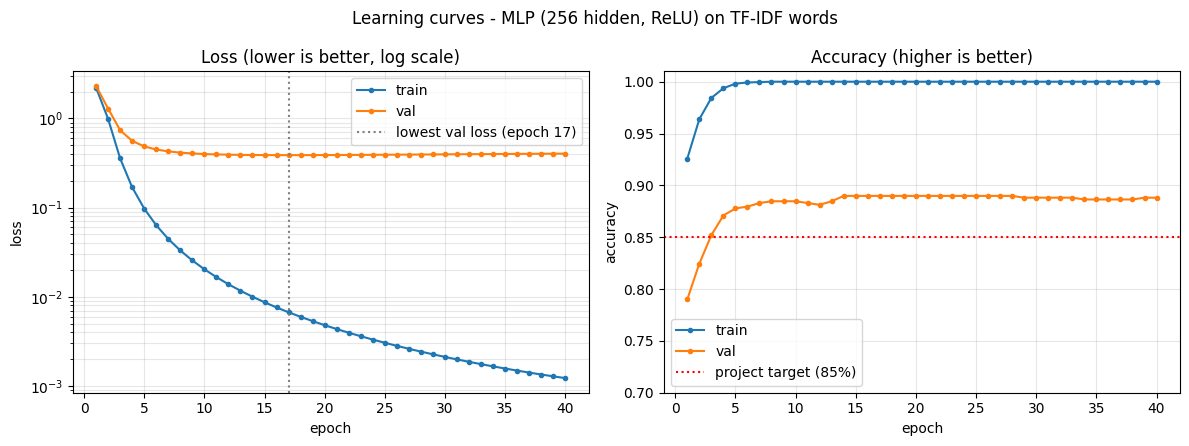

In [3]:
import warnings
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import log_loss, accuracy_score

mlp = MLPClassifier(hidden_layer_sizes=(256,), activation="relu", solver="adam",
                    learning_rate_init=0.001, batch_size=32, alpha=0.0001, random_state=42)

EPOCHS = 40
curves = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
for epoch in range(1, EPOCHS + 1):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")                       # silence "one epoch only" convergence warnings
        mlp.partial_fit(X_train, y_train, classes=SUBCATEGORIES)
    curves["train_loss"].append(log_loss(y_train, mlp.predict_proba(X_train), labels=mlp.classes_))
    curves["val_loss"].append(log_loss(y_val, mlp.predict_proba(X_val), labels=mlp.classes_))
    curves["train_acc"].append(accuracy_score(y_train, mlp.predict(X_train)))
    curves["val_acc"].append(accuracy_score(y_val, mlp.predict(X_val)))

best_epoch = curves["val_loss"].index(min(curves["val_loss"])) + 1
print(f"{'epoch':>5} | {'train loss':>10} {'val loss':>9} | {'train acc':>9} {'val acc':>8}")
for e in [e for e in [1, 2, 3, 5, 8, 10, 15, 20, 30, 40] if e <= EPOCHS]:
    i = e - 1
    mark = "  <- lowest val loss" if e == best_epoch else ""
    print(f"{e:5d} | {curves['train_loss'][i]:10.4f} {curves['val_loss'][i]:9.4f} | "
          f"{curves['train_acc'][i]:9.2%} {curves['val_acc'][i]:8.2%}{mark}")
print(f"\nLowest val loss at epoch {best_epoch}: {min(curves['val_loss']):.4f} "
      f"(val accuracy {curves['val_acc'][best_epoch - 1]:.2%})")

epochs = range(1, EPOCHS + 1)
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4.5))
ax_loss.plot(epochs, curves["train_loss"], "o-", ms=3, label="train")
ax_loss.plot(epochs, curves["val_loss"], "o-", ms=3, label="val")
ax_loss.axvline(best_epoch, color="gray", linestyle=":", label=f"lowest val loss (epoch {best_epoch})")
ax_loss.set_yscale("log")
ax_loss.set(title="Loss (lower is better, log scale)", xlabel="epoch", ylabel="loss")
ax_acc.plot(epochs, curves["train_acc"], "o-", ms=3, label="train")
ax_acc.plot(epochs, curves["val_acc"], "o-", ms=3, label="val")
ax_acc.axhline(0.85, color="red", linestyle=":", label="project target (85%)")
ax_acc.set(title="Accuracy (higher is better)", xlabel="epoch", ylabel="accuracy", ylim=(0.7, 1.01))
for ax in (ax_loss, ax_acc):
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()
fig.suptitle("Learning curves - MLP (256 hidden, ReLU) on TF-IDF words")
fig.tight_layout()
FIGURES = ROOT / "eval" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGURES / "classifier_learning_curves_v1.png", dpi=150)
plt.show()

### Diagnosis of the first MLP
**Overfitting**, and more precisely **shortcut learning from templated data**:
- train reaches **100%** (loss 0.001) while val stays at **~89%** (loss 0.39), and val loss goes back up after ~17 epochs;
- the training set has **1,524 template rows made from only 575 templates** (~2.7 near-copies of each sentence skeleton), so memorizing train is trivial;
- the model learned **skeletons** instead of intent words, e.g. `should i bring cash to <loc>` and `il faut prendre du liquide pour <loc>` (payment) → predicted **weather**, because weather templates say "Should I **bring** a jacket **to** <LOC>" / "Je dois **prendre** une veste **pour** <LOC>";
- **36–44% of val messages contain a word never seen in train** (Tunisian is the highest), and a from-scratch model knows nothing outside its training data;
- **41% of the mistakes stay inside the same category** (e.g. flight_price ↔ flight_search on "cheap flight…", "promotions on flights…"): partly a genuine overlap between classes.

## 3. Fixing it: a tuning grid of general fixes

Rule: we only try **general** fixes. We do **not** write new training sentences by looking at val mistakes, because that would turn val into training data and make it a dishonest test.

| fix | values tried | why it should help |
|---|---|---|
| **template copies in train** | all (~2.7 per template) / **at most 1 per template** | removes repeated skeletons, so the model must rely on intent words |
| **features** | words / words + word pairs / **words + character pieces (2–5)** | pairs add short phrases (`9adech el`); character pieces handle spelling variants and partly-unseen words (`karhabet` ↔ `karhba`) |
| **L2 penalty `alpha`** | 0.0001 / 0.001 / 0.01 | makes big weights "expensive": simpler, more general rules |
| **hidden neurons** | 64 for the whole grid, then **256 for the best setting** | fewer weights = less room to memorize (and 256 neurons is ~4× slower to train) |

**Early stopping** for every setting: train up to 20 epochs, measure val loss after each epoch, keep the epoch with the lowest val loss, and stop after 3 epochs without improvement.

Each setting is scored on val with **macro F1** (the average F1 over the 15 subcategories, the brief's metric). Choosing settings on val makes the val score slightly optimistic; the **test** set at the very end gives the honest final number. The grid has 18 settings plus 1 (the best one with 256 neurons) and takes about 10–15 minutes. (A first version with 36 settings and 256 neurons everywhere took more than an hour: with word pairs or character pieces, 256 neurons cost 11–17 seconds per epoch.)

In [4]:
import copy, time, math
import numpy as np
from sklearn.pipeline import FeatureUnion
from sklearn.metrics import f1_score

WORD_PATTERN = r"(?u)\b\w+\b"

def make_vectorizer(features):
    if features == "words":
        return TfidfVectorizer(token_pattern=WORD_PATTERN)
    if features == "words+pairs":
        return TfidfVectorizer(token_pattern=WORD_PATTERN, ngram_range=(1, 2))
    if features == "words+chars":
        return FeatureUnion([
            ("words", TfidfVectorizer(token_pattern=WORD_PATTERN)),
            ("chars", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True)),
        ])
    raise ValueError(features)

def train_rows(one_copy_per_template):
    # keep every GPT row; for template rows keep only the first row of each template if asked
    if not one_copy_per_template:
        return train
    seen, rows = set(), []
    for r in train:
        if r["template_id"] is None or r["template_id"] not in seen:
            rows.append(r)
            seen.add(r["template_id"])
    return rows

def train_with_early_stopping(Xtr, ytr, Xva, yva, hidden, alpha, max_epochs=20, patience=3):
    mlp = MLPClassifier(hidden_layer_sizes=(hidden,), activation="relu", solver="adam",
                        learning_rate_init=0.001, batch_size=32, alpha=alpha, random_state=42)
    best, best_loss, best_epoch, history = None, math.inf, 0, []
    for epoch in range(1, max_epochs + 1):
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            mlp.partial_fit(Xtr, ytr, classes=SUBCATEGORIES)
        val_loss = log_loss(yva, mlp.predict_proba(Xva), labels=mlp.classes_)
        history.append(val_loss)
        if val_loss < best_loss:
            best, best_loss, best_epoch = copy.deepcopy(mlp), val_loss, epoch
        elif epoch - best_epoch >= patience:
            break                                              # early stopping
    return best, best_epoch, best_loss

grid, best_overall, start = [], None, time.time()
for one_copy in [False, True]:
    rows = train_rows(one_copy)
    texts, labels = [normalize(r["text_masked"]) for r in rows], [r["subcategory"] for r in rows]
    for features in ["words", "words+pairs", "words+chars"]:
        vec = make_vectorizer(features)
        Xtr, Xva = vec.fit_transform(texts), vec.transform(X_val_text)       # fitted on train only
        for alpha in [0.0001, 0.001, 0.01]:
            hidden = 64
            model, ep, vloss = train_with_early_stopping(Xtr, labels, Xva, y_val, hidden, alpha)
            pred = model.predict(Xva)
            res = {"one_copy_per_template": one_copy, "features": features, "alpha": alpha, "hidden": hidden,
                   "train_rows": len(rows), "best_epoch": ep, "val_loss": vloss,
                   "val_acc": accuracy_score(y_val, pred), "val_macro_f1": f1_score(y_val, pred, average="macro")}
            grid.append(res)
            if best_overall is None or res["val_macro_f1"] > best_overall[0]["val_macro_f1"]:
                best_overall = (res, model, vec)
    print(f"  one copy per template = {one_copy}: done ({time.time() - start:.0f} s)")

# the best setting again, with 256 hidden neurons
b = best_overall[0]
rows = train_rows(b["one_copy_per_template"])
texts, labels = [normalize(r["text_masked"]) for r in rows], [r["subcategory"] for r in rows]
vec = make_vectorizer(b["features"])
Xtr, Xva = vec.fit_transform(texts), vec.transform(X_val_text)
model, ep, vloss = train_with_early_stopping(Xtr, labels, Xva, y_val, 256, b["alpha"])
pred = model.predict(Xva)
res = {**b, "hidden": 256, "best_epoch": ep, "val_loss": vloss,
       "val_acc": accuracy_score(y_val, pred), "val_macro_f1": f1_score(y_val, pred, average="macro")}
grid.append(res)
if res["val_macro_f1"] > b["val_macro_f1"]:
    best_overall = (res, model, vec)
print(f"  best setting with 256 neurons: done ({time.time() - start:.0f} s)")

grid.sort(key=lambda r: -r["val_macro_f1"])
print(f"\n{'copies':>6} {'features':12s} {'alpha':>7} {'hidden':>6} | {'rows':>5} {'epoch':>5} | {'val loss':>8} {'val acc':>7} {'macro F1':>8}")
for r in grid:
    print(f"{'1' if r['one_copy_per_template'] else 'all':>6} {r['features']:12s} {r['alpha']:7.4f} {r['hidden']:6d} | "
          f"{r['train_rows']:5d} {r['best_epoch']:5d} | {r['val_loss']:8.4f} {r['val_acc']:7.2%} {r['val_macro_f1']:8.2%}")
first = next(r for r in grid if not r["one_copy_per_template"] and r["features"] == "words" and r["alpha"] == 0.0001)
print(f"\nClosest to the first MLP (all copies, words, alpha 0.0001, 64 neurons): macro F1 {first['val_macro_f1']:.2%}")

  one copy per template = False: done (366 s)


  one copy per template = True: done (590 s)


  best setting with 256 neurons: done (851 s)

copies features       alpha hidden |  rows epoch | val loss val acc macro F1
   all words+chars   0.0001     64 |  2680    20 |   0.2767  93.12%   93.19%
     1 words+chars   0.0001     64 |  1731    20 |   0.2889  92.60%   92.57%
   all words+chars   0.0001    256 |  2680    18 |   0.2665  92.43%   92.48%
   all words+chars   0.0010     64 |  2680    20 |   0.2909  91.91%   92.01%
     1 words+chars   0.0010     64 |  1731    20 |   0.3021  91.91%   91.89%
     1 words+chars   0.0100     64 |  1731    20 |   0.3713  91.74%   91.72%
   all words+chars   0.0100     64 |  2680    20 |   0.3515  91.05%   91.14%
   all words         0.0100     64 |  2680    20 |   0.4516  89.33%   89.36%
   all words         0.0001     64 |  2680    20 |   0.4083  88.47%   88.47%
   all words         0.0010     64 |  2680    20 |   0.4134  88.47%   88.47%
     1 words         0.0001     64 |  1731    20 |   0.4464  86.75%   86.82%
     1 words         0.0100  

## 4. The final model: detailed evaluation on val

The best setting of the grid (highest val macro F1) is kept. For it we report:
- **accuracy** and **macro F1** (target: > 85%);
- **category accuracy**: is at least the category right? (confusing `flight_search` with `flight_price` is less harmful than with `weather`);
- **accuracy per language**;
- **precision / recall / F1 per subcategory**;
- the **15 × 15 confusion matrix** (rows = true subcategory, columns = predicted);
- the remaining **mistakes**, grouped by the most frequent confusions.

Final setting: {'one_copy_per_template': False, 'features': 'words+chars', 'alpha': 0.0001, 'hidden': 64, 'best_epoch': 20}

VAL accuracy 93.12% | macro F1 93.19% | category accuracy 97.07%
Accuracy per language: en 91.10%  fr 92.86%  tn_latin 95.36%

                  precision    recall  f1-score   support

   flight_search      0.706     0.923     0.800        39
    flight_price      0.903     0.700     0.789        40
         baggage      0.949     1.000     0.974        37
    hotel_search      0.905     0.950     0.927        40
     hotel_price      0.973     0.947     0.960        38
hotel_facilities      0.917     0.917     0.917        36
      car_rental      0.974     0.949     0.961        39
   transfer_taxi      1.000     0.947     0.973        38
public_transport      0.974     0.927     0.950        41
         weather      0.974     1.000     0.987        37
      activities      0.902     0.925     0.914        40
  visa_documents      0.949     0.925     0.937    

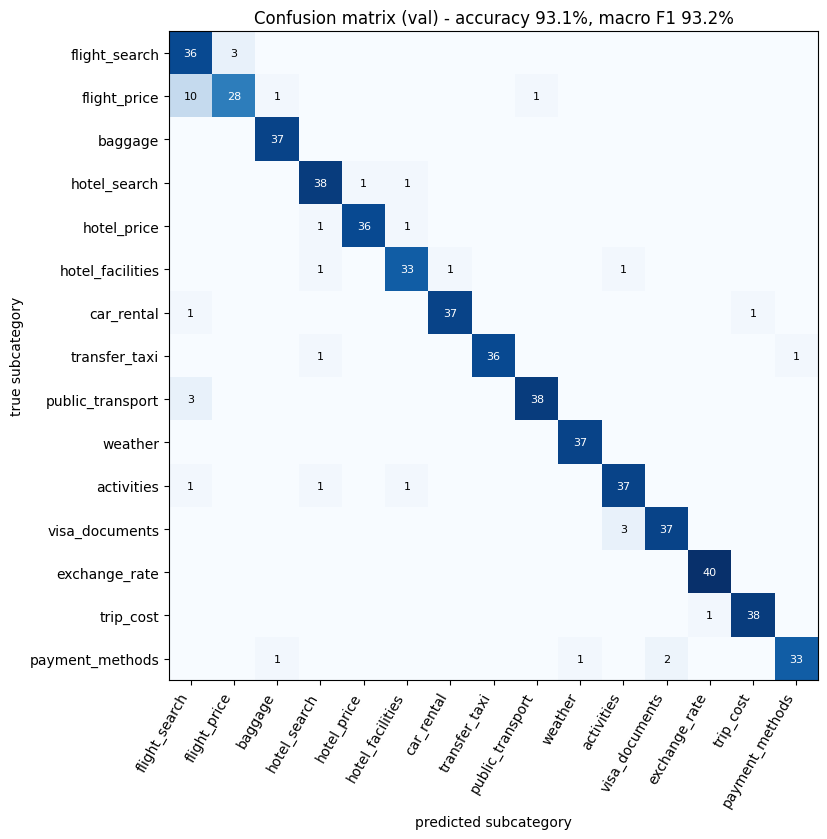

40 mistakes; most frequent confusions:
  10x  flight_price      -> flight_search
        | Any promotions on flights to Sidi Bou Said?
   3x  flight_search     -> flight_price
        | What's the next flight to Hammamet?
   3x  visa_documents    -> activities
        | What vaccines do I need for Dubai?
   3x  public_transport  -> flight_search
        | Il y a un bac pour aller à Zarzis?
   2x  payment_methods   -> visa_documents
        | Il faut prendre du liquide pour Mahdia
   1x  car_rental        -> trip_cost
        | How much is a small car for 8 days in Jeddah
   1x  payment_methods   -> weather
        | should i bring cash to barcelona?
   1x  payment_methods   -> baggage
        | Il faut prendre du liquide pour Bizerte ?


In [5]:
from sklearn.metrics import classification_report, confusion_matrix

best_res, final_model, final_vec = best_overall
print("Final setting:", {k: best_res[k] for k in ["one_copy_per_template", "features", "alpha", "hidden", "best_epoch"]})
X_val_final = final_vec.transform(X_val_text)
val_pred = final_model.predict(X_val_final)

acc = accuracy_score(y_val, val_pred)
macro_f1 = f1_score(y_val, val_pred, average="macro")
cat_acc = np.mean([SUBCAT_TO_CAT[t] == SUBCAT_TO_CAT[p] for t, p in zip(y_val, val_pred)])
print(f"\nVAL accuracy {acc:.2%} | macro F1 {macro_f1:.2%} | category accuracy {cat_acc:.2%}")
per_lang = {}
for lang in LANGS:
    idx = [i for i, r in enumerate(val) if r["lang"] == lang]
    per_lang[lang] = accuracy_score([y_val[i] for i in idx], [val_pred[i] for i in idx])
print("Accuracy per language:", "  ".join(f"{l} {a:.2%}" for l, a in per_lang.items()))
print()
print(classification_report(y_val, val_pred, labels=SUBCATEGORIES, digits=3, zero_division=0))

cm = confusion_matrix(y_val, val_pred, labels=SUBCATEGORIES)
fig, ax = plt.subplots(figsize=(10, 8.5))
ax.imshow(cm, cmap="Blues")
for i in range(len(SUBCATEGORIES)):
    for j in range(len(SUBCATEGORIES)):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks(range(15), SUBCATEGORIES, rotation=60, ha="right")
ax.set_yticks(range(15), SUBCATEGORIES)
ax.set(xlabel="predicted subcategory", ylabel="true subcategory",
       title=f"Confusion matrix (val) - accuracy {acc:.1%}, macro F1 {macro_f1:.1%}")
fig.tight_layout()
fig.savefig(FIGURES / "classifier_confusion_matrix.png", dpi=150)
plt.show()

errors = Counter((t, p) for t, p in zip(y_val, val_pred) if t != p)
print(f"{sum(errors.values())} mistakes; most frequent confusions:")
for (t, p), n in errors.most_common(8):
    print(f"  {n:2d}x  {t:17s} -> {p}")
    for r, pr in zip(val, val_pred):
        if r["subcategory"] == t and pr == p:
            print(f"        | {r['text']}")
            break

## 5. Which words does the model really listen to?

Earlier question: `el` has a TF-IDF value close to `9adech`, but `9adech` is much more useful. TF-IDF is only "how loud" a word is; **the MLP's weights decide how much the model listens to it**.

Simple way to measure it (*occlusion*): for each val message, **remove one word** and see how much the probability of the predicted subcategory drops. A word the model relies on causes a big drop; a word it ignores causes almost none. We average this over all val messages containing the word.

In [6]:
import re
from collections import defaultdict

base = final_model.predict_proba(final_vec.transform(X_val_text))
pred_idx = base.argmax(axis=1)
variants, owners = [], []
for i, text in enumerate(X_val_text):
    for w in set(re.findall(WORD_PATTERN, text)):
        variants.append(re.sub(rf"(?u)\b{re.escape(w)}\b", " ", text))
        owners.append((i, w))
probs_without = final_model.predict_proba(final_vec.transform(variants))
drops = defaultdict(list)
for (i, w), p in zip(owners, probs_without):
    drops[w].append(base[i, pred_idx[i]] - p[pred_idx[i]])

print("Average probability drop when the word is removed:")
for w in ["el", "the", "le", "loc", "9adech", "combien", "much", "billet", "hotel", "valise", "météo", "karhba"]:
    if w in drops:
        print(f"   {w:8s} {np.mean(drops[w]):+.3f}   (in {len(drops[w])} val messages)")
frequent = {w: np.mean(d) for w, d in drops.items() if len(d) >= 8}
print("\n15 words the model relies on most (seen in >= 8 val messages):")
print("  ", ", ".join(f"{w} ({v:+.2f})" for w, v in sorted(frequent.items(), key=lambda t: -t[1])[:15]))
print("\n10 words it nearly ignores:")
print("  ", ", ".join(f"{w} ({v:+.3f})" for w, v in sorted(frequent.items(), key=lambda t: abs(t[1]))[:10]))

Average probability drop when the word is removed:
   el       -0.002   (in 32 val messages)
   the      +0.009   (in 45 val messages)
   le       +0.011   (in 31 val messages)
   loc      +0.007   (in 473 val messages)
   9adech   +0.077   (in 33 val messages)
   combien  +0.018   (in 19 val messages)
   much     +0.117   (in 16 val messages)
   billet   +0.138   (in 11 val messages)
   hotel    +0.119   (in 64 val messages)
   valise   +0.486   (in 6 val messages)
   météo    +0.514   (in 3 val messages)
   karhba   +0.422   (in 7 val messages)

15 words the model relies on most (seen in >= 8 val messages):
   train (+0.75), taxi (+0.68), visa (+0.47), louage (+0.42), vols (+0.36), flight (+0.33), flights (+0.32), vol (+0.27), prix (+0.19), bagage (+0.19), car (+0.17), euros (+0.16), hôtel (+0.15), billet (+0.14), kifech (+0.12)

10 words it nearly ignores:
   is (-0.000), station (+0.000), en (+0.001), d (+0.001), air (-0.002), men (-0.002), per (+0.002), à (-0.002), of (-0.002), el

## 6. Save the model and its metrics

- `models/classifier/mlp_tfidf.joblib`: the fitted TF-IDF vectorizer **and** the MLP (both are needed to classify a new message);
- `eval/metrics/classifier_mlp_tfidf.json`: the settings, the val metrics and the whole grid;
- the chatbot uses `src/classifier/classify.py`: `classify(text_masked)` → subcategory, category, confidence and the top 2.

In [7]:
import joblib

MODEL_DIR = ROOT / "models" / "classifier"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
settings = {k: best_res[k] for k in ["one_copy_per_template", "features", "alpha", "hidden", "best_epoch"]}
joblib.dump({"vectorizer": final_vec, "mlp": final_model, "settings": settings}, MODEL_DIR / "mlp_tfidf.joblib")

report = classification_report(y_val, val_pred, labels=SUBCATEGORIES, output_dict=True, zero_division=0)
metrics = {"model": "MLP on TF-IDF (scikit-learn)", "settings": settings, "set": "val",
           "accuracy": acc, "macro_f1": macro_f1, "category_accuracy": float(cat_acc),
           "accuracy_per_language": per_lang,
           "per_subcategory": {s: report[s] for s in SUBCATEGORIES},
           "grid": grid}
with open(ROOT / "eval" / "metrics" / "classifier_mlp_tfidf.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2)
print("Saved models/classifier/mlp_tfidf.joblib and eval/metrics/classifier_mlp_tfidf.json")

from src.classifier.classify import classify
for msg in ["9adech el billet l <LOC> <DATE> ?", "should i bring cash to <LOC> ?",
            "il fait quel temps a <LOC> <DATE> ?", "nheb nkri karhba f <LOC>"]:
    print(f"  {msg:40s} -> {classify(msg)}")

Saved models/classifier/mlp_tfidf.joblib and eval/metrics/classifier_mlp_tfidf.json
  9adech el billet l <LOC> <DATE> ?        -> {'subcategory': 'flight_price', 'category': 'flights', 'confidence': 0.9921556856043576, 'top2': [('flight_price', 0.9921556856043576), ('public_transport', 0.005821404319203928)]}
  should i bring cash to <LOC> ?           -> {'subcategory': 'weather', 'category': 'destination_info', 'confidence': 0.21867040853509742, 'top2': [('weather', 0.21867040853509742), ('payment_methods', 0.2112646884809598)]}
  il fait quel temps a <LOC> <DATE> ?      -> {'subcategory': 'weather', 'category': 'destination_info', 'confidence': 0.9997757133733057, 'top2': [('weather', 0.9997757133733057), ('activities', 9.462521852515564e-05)]}
  nheb nkri karhba f <LOC>                 -> {'subcategory': 'car_rental', 'category': 'local_transport', 'confidence': 0.9998188416499527, 'top2': [('car_rental', 0.9998188416499527), ('flight_search', 6.33968453237771e-05)]}


## 7. Conclusions (val set)

| | first MLP (words, 256 neurons, 40 epochs) | **final MLP** |
|---|---|---|
| Features | whole words | **whole words + character pieces (2–5)** |
| Hidden neurons / alpha | 256 / 0.0001 | **64 / 0.0001** |
| Epochs | 40 | 20 (early stopping on val loss) |
| Val accuracy | 88.8% | **93.1%** |
| Val macro F1 | — | **93.2%** (target > 85% ✅) |
| Category accuracy | — | **97.1%** |
| Accuracy per language | — | en 91.1% · fr 92.9% · tn **95.4%** |

**What helped, and what did not:**
- **Character pieces were the key fix** (+4–5 points): they let the model recognise spelling variants and partly-unseen words (`karhabet` ↔ `karhba`, `gouter` ↔ `goûter`), which matters a lot for Tunisian Arabizi (now the best language).
- **Word pairs hurt** (~84%): they multiply the vocabulary with pairs seen only once or twice, i.e. more things to memorize.
- **One copy per template did not help** (slightly worse): removing repeated skeletons also removed ~35% of the training data, and losing data cost more than the repetition did.
- **Stronger L2 and 256 neurons did not help either**: 64 neurons with a small penalty was the best.
- The best model stopped at the **20-epoch limit** with val loss still slowly improving, so a few more epochs might gain a little.

**What still goes wrong (40 mistakes out of 581):**
- **flight_price ↔ flight_search (13 of the 40)**: "Any promotions on flights…", "What's the next flight…". These two classes genuinely overlap; a clear labelling rule ("any mention of price, cheap, promotion → flight_price") would remove most of these, and **category accuracy (97.1%)** shows the model almost always gets the *flights* part right.
- A few remaining **skeleton shortcuts**: `should i bring cash to <loc>` → weather (22%) vs payment (21%), a near tie. The orchestrator can use `top2` to ask the user when the two best answers are this close.
- Occasional cross-category confusions (visa ↔ activities for vaccines, ferry → flight).

**Which words matter (occlusion):** removing `el`, `the` or `le` changes the prediction by ~0.01, while removing `valise`, `météo`, `karhba`, `train`, `taxi` or `visa` changes it by 0.4–0.75. **The MLP learned to ignore frequent function words**, even though their TF-IDF values are not small.

**Honesty note:** the settings were chosen on val, so the val numbers are slightly optimistic. The **test set**, used once at the end of the project, will give the final score.